In [21]:
import os
import sys
import numpy as np

In [3]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), os.pardir)))

In [4]:
from lung_nodule_detection_luna16.dsets import getCandidateInfoList, getCt, LunaDataset

In [5]:
candidateInfo_list = getCandidateInfoList(require_on_disk=False)

In [6]:
positiveInfo_list = [x for x in candidateInfo_list if x[0]]
diameter_list = [x[1] for x in positiveInfo_list]

In [7]:
for i in range(0, len(diameter_list), 100):
    print('{:4} {:4.1f} mm'.format(i, diameter_list[i]))

   0 32.3 mm
 100 17.7 mm
 200 13.0 mm
 300 10.0 mm
 400  8.2 mm
 500  7.0 mm
 600  6.3 mm
 700  5.7 mm
 800  5.1 mm
 900  4.7 mm
1000  4.0 mm
1100  0.0 mm
1200  0.0 mm
1300  0.0 mm


In [8]:
from lung_nodule_detection_luna16.vis import findPositiveSamples, showCandidate

In [9]:
positiveSample_list = findPositiveSamples()

0 CandidateInfoTuple(isNodule_bool=True, diameter_mm=32.27003025, series_uid='1.3.6.1.4.1.14519.5.2.1.6279.6001.287966244644280690737019247886', center_xyz=(67.61451718, 85.02525992, -109.8084416))
1 CandidateInfoTuple(isNodule_bool=True, diameter_mm=25.23320204, series_uid='1.3.6.1.4.1.14519.5.2.1.6279.6001.511347030803753100045216493273', center_xyz=(63.4740118048, 73.9174523314, -213.736128767))
2 CandidateInfoTuple(isNodule_bool=True, diameter_mm=23.35064438, series_uid='1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636438705059720603192', center_xyz=(57.42, 81.14, -118.09))
3 CandidateInfoTuple(isNodule_bool=True, diameter_mm=23.35064438, series_uid='1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636438705059720603192', center_xyz=(56.4889724157, 85.9418105037, -115.9731945))
4 CandidateInfoTuple(isNodule_bool=True, diameter_mm=23.35064438, series_uid='1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636438705059720603192', center_xyz=(50.4361084414, 90.0424445754, -113.908439345))
5 Candidate

In [10]:
series_uid = positiveSample_list[11][2]


In [11]:
showCandidate(series_uid)

1.3.6.1.4.1.14519.5.2.1.6279.6001.752756872840730509471096155114 0 False [0, 1]


<IPython.core.display.Javascript object>

In [12]:
lunaDataset = LunaDataset()

In [13]:
LunaDataset?

Init signature: LunaDataset(val_stride=0, isValSet_bool=None, series_uid=None)
Docstring:     
An abstract class representing a :class:`Dataset`.

All datasets that represent a map from keys to data samples should subclass
it. All subclasses should overwrite :meth:`__getitem__`, supporting fetching a
data sample for a given key. Subclasses could also optionally overwrite
:meth:`__len__`, which is expected to return the size of the dataset by many
:class:`~torch.utils.data.Sampler` implementations and the default options
of :class:`~torch.utils.data.DataLoader`. Subclasses could also
optionally implement :meth:`__getitems__`, for speedup batched samples
loading. This method accepts list of indices of samples of batch and returns
list of samples.

.. note::
  :class:`~torch.utils.data.DataLoader` by default constructs an index
  sampler that yields integral indices.  To make it work with a map-style
  dataset with non-integral indices/keys, a custom sampler must be provided.
File:       

In [14]:
len(lunaDataset)

110143

In [15]:
out = lunaDataset[0]

In [16]:
type(out)

tuple

In [17]:
out[0].shape

torch.Size([1, 32, 48, 48])

In [18]:
import matplotlib.pyplot as plt
%matplotlib inline

In [19]:
# Initialize dataset
ds = LunaDataset(val_stride=10, isValSet_bool=False)

# Pick the first positive nodule sample (change sample_ndx to inspect any other candidate)
pos_indices = [
    i for i, tup in enumerate(ds.candidateInfo_list) if tup.isNodule_bool
]
sample_ndx = pos_indices[0] if pos_indices else 0

# Fetch the sample
candidate_t, pos_t, series_uid, center_irc = ds[sample_ndx]

# Convert from (1, 32, 48, 48) tensor to (32, 48, 48) NumPy array [Index, Row, Col]
ct_crop = candidate_t.squeeze(0).numpy()
is_nodule = bool(pos_t[1].item())

print(f"Sample index: {sample_ndx}")
print(f"Series UID:   {series_uid}")
print(f"Center (IRC): {center_irc.tolist()}")
print(f"Is Nodule:    {is_nodule}")
print(f"Crop shape:   {ct_crop.shape}")

Sample index: 0
Series UID:   1.3.6.1.4.1.14519.5.2.1.6279.6001.511347030803753100045216493273
Center (IRC): [68, 383, 349]
Is Nodule:    True
Crop shape:   (32, 48, 48)


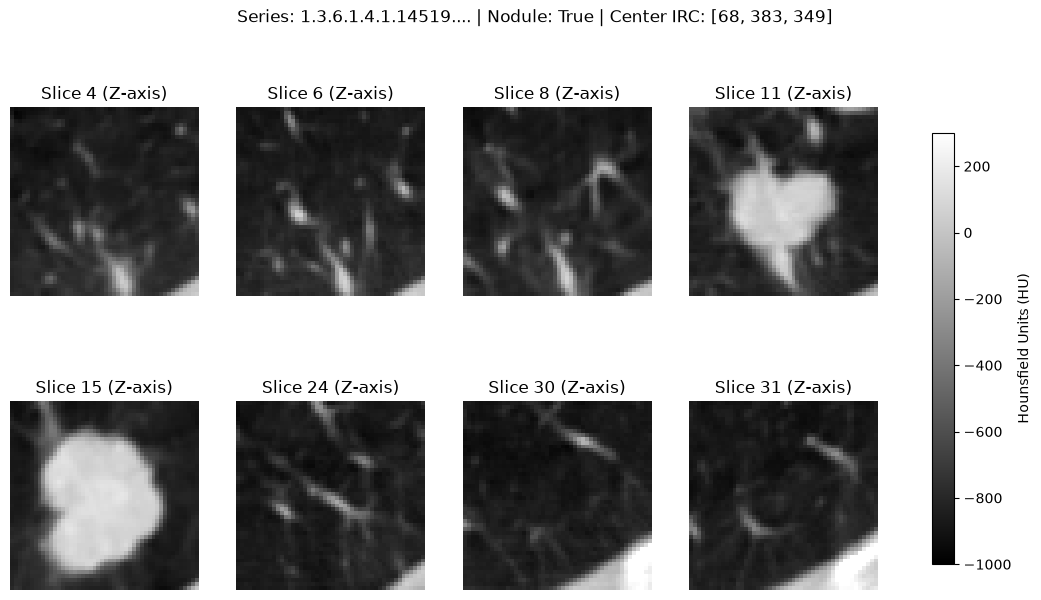

In [22]:
num_slices = 8
random_indices = np.sort(
    np.random.choice(ct_crop.shape[0], size=num_slices, replace=False)
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle(
    f"Series: {series_uid[:18]}... | Nodule: {is_nodule} | Center IRC: {center_irc.tolist()}",
    fontsize=12,
)

for ax, slice_idx in zip(axes.flat, random_indices):
  im = ax.imshow(ct_crop[slice_idx], cmap="gray", vmin=-1000, vmax=300)
  ax.set_title(f"Slice {slice_idx} (Z-axis)")
  ax.axis("off")

fig.colorbar(
    im, ax=axes.ravel().tolist(), shrink=0.8, label="Hounsfield Units (HU)"
)
plt.show()